# Question 3: Research document mining

This notebook loads every supplied article, denoises its content, and produces two extractive summaries with visualisations. Run from top to bottom. Original text is retained for auditing; readable denoised sentences are used for the summaries, and their lemmatised, stop-word-filtered versions are used for scoring.

## 3.1 Load the complete article dataframe

Keep all supplied files, including duplicate files, to preserve the assigned corpus. SHA-256 hashes identify identical documents without deleting or replacing them. The supplied texts concern research methodology and education; the analysis reports their actual content rather than assuming that they are AI papers.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

project_dir = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / 'Dataset' / 'research_corpus').is_dir()
)
corpus_dir = project_dir / 'Dataset' / 'research_corpus'
files = sorted(corpus_dir.glob('*.txt'))
if not files:
    raise FileNotFoundError(f'No article text files found in {corpus_dir}')

records = []
first_file_for_hash = {}
for file in files:
    raw_bytes = file.read_bytes()
    content_hash = hashlib.sha256(raw_bytes).hexdigest()
    records.append({
        'file_name': file.name,
        'text': raw_bytes.decode('utf-8'),
        'content_hash': content_hash,
        'duplicate_of': first_file_for_hash.get(content_hash, ''),
    })
    first_file_for_hash.setdefault(content_hash, file.name)

df = pd.DataFrame(records)
df['raw_characters'] = df['text'].str.len()
print(f'Loaded {len(df)} files; {df["content_hash"].nunique()} distinct document contents.')
display(df[['file_name', 'raw_characters', 'duplicate_of']])
print('Each row retains its complete original content in the text column.')
display(df[['file_name', 'text']].head())
if df['duplicate_of'].ne('').any():
    print('Dataset warning: identical files are retained, not counted as independent evidence.')
    display(df.loc[df['duplicate_of'].ne(''), ['file_name', 'duplicate_of']])

Loaded 5 files; 4 distinct document contents.


,file_name,raw_characters,duplicate_of
0,research_1.txt,38598,
1,research_2.txt,38598,research_1.txt
2,research_3.txt,16279,
3,research_4.txt,26521,
4,research_5.txt,39072,


Each row retains its complete original content in the text column.


,file_name,text
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,The purposes of this article are to position m...
2,research_3.txt,"Now I see it, now I don’t:\r\nresearcher’s pos..."
3,research_4.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCT...
4,research_5.txt,Abstract\r\nCronbach’s alpha is a statistic co...


Dataset warning: identical files are retained, not counted as independent evidence.


,file_name,duplicate_of
1,research_2.txt,research_1.txt


## 3.2 Document-aware text denoising

The pipeline applies Unicode normalisation, removes control characters, joins words split by line-end hyphens, and removes URLs, contact details, bibliographic citations, page headers, section/table headings and fragmented table blocks and embedded footnotes. Where present, an explicit Abstract or Introduction heading identifies the start of the article body. Repeated sentences are removed within each article.

Sentence boundaries and punctuation are retained in `denoised_sentences` for readable extraction. POS-aware WordNet lemmatisation and English stop-word removal produce corresponding `model_sentences` for TF-IDF and LSA; both summaries therefore use the denoised content. Short fragments and unusually long extraction artefacts are excluded from summary candidates, while the dataframe retains the cleaned article body.

These are transparent, corpus-aware preprocessing rules, not a claim that every PDF/OCR error can be recovered. The audit below reports what was removed and preserves the raw text for inspection.

In [2]:
import re
import unicodedata
import numpy as np
import nltk
from nltk import pos_tag, sent_tokenize, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

for resource, location in [
    ('punkt_tab', 'tokenizers/punkt_tab'),
    ('averaged_perceptron_tagger_eng', 'taggers/averaged_perceptron_tagger_eng'),
    ('wordnet', 'corpora/wordnet.zip'),
]:
    try:
        nltk.data.find(location)
    except LookupError:
        nltk.download(resource, raise_on_error=True)

lemmatizer = WordNetLemmatizer()

def sentence_key(text):
    return ' '.join(re.findall(r"[a-z]+", text.lower()))

def denoise_article(text):
    text = unicodedata.normalize('NFKC', text)
    text = text.translate(str.maketrans({
        '\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
        '\u2013': ' - ', '\u2014': ' - ', '\ufeff': '', '\u03b1': ' alpha ',
    }))
    text = ''.join(
        char if not unicodedata.category(char).startswith('C') or char in '\n\r\t' else ' '
        for char in text
    )
    text = re.sub(r'(?<=[a-z])-\s*\n\s*(?=[a-z])', '', text)
    lines = text.splitlines()
    body_start = 0
    for index, line in enumerate(lines[:30]):
        if re.fullmatch(r'\s*(?:abstract|(?:\d+(?:\.\d+)*\s+)?introduction)\s*', line, re.I):
            body_start = index + 1
            break

    kept_lines = []
    in_table = False
    in_footnote = False
    skip_next = False
    removed_lines = body_start
    for line_number, line in enumerate(lines[body_start:], start=body_start):
        line = line.strip()
        if skip_next:
            skip_next = False
            removed_lines += 1
            continue
        if not line:
            continue
        if in_footnote or re.match(r'^[1-9]\d?(?=[A-Z])', line):
            in_footnote = not bool(re.search(r'[.!?][\"\']?$', line))
            removed_lines += 1
            continue
        if re.fullmatch(r'(?:references|bibliography|works cited)', line, re.I):
            removed_lines += len(lines) - line_number
            break
        if re.match(r'^(?:corresponding author|keywords)\s*:?$', line, re.I):
            skip_next = True
            removed_lines += 1
            continue
        if (re.match(r'^(?:TABLE|FIGURE)\s+\d', line)
                or re.fullmatch(r'(?:table|figure)\s+\d+(?:\.\d+)*\.?', line, re.I)):
            in_table = True
            removed_lines += 1
            continue
        # Tables in these text exports contain short fragments; resume at prose.
        if in_table:
            is_prose = (len(line.split()) >= 12 and re.search(r'[.!?](?:\s|$)', line))
            if is_prose or (re.match(r'^[a-z]', line) and len(line.split()) >= 8 and '&' not in line):
                in_table = False
            else:
                removed_lines += 1
                continue
        words = re.findall(r"[A-Za-z][A-Za-z'-]*", line)
        is_title = (2 <= len(words) <= 16
                    and sum(word[0].isupper() for word in words) / len(words) >= 0.65
                    and not re.search(r'[.!?;]$', line))
        is_header = (
            is_title
            or
            re.fullmatch(r'\d{1,4}', line)
            or re.fullmatch(r'[A-Z][a-z]+\s+\d{2,4}', line)
            or re.match(r'^\d+\s+Qualitative Research\b', line)
            or (line.isupper() and len(line.split()) <= 14)
            or re.match(r'^\d+(?:\.\d+)+\s+[A-Z]', line)
            or re.match(r'^\d+\.\s+DEVELOPMENTAL RESEARCH\b', line)
            or re.match(r'^(?:by |Email:|https?://|doi:|Copyright|Article$|Full size image$)', line, re.I)
            or re.match(r'^\d{6,}\w*10\.\d{4,}/', line)
        )
        if is_header:
            removed_lines += 1
            continue
        kept_lines.append(line)

    body = re.sub(r'https?://\S+|www\.\S+|[\w.+-]+@[\w.-]+\.\w+', ' ', ' '.join(kept_lines))
    # Remove parenthetical citations containing a publication year, not all parentheses.
    for _ in range(2):
        body = re.sub(r'\([^()]*\b(?:18|19|20)\d{2}[a-z]?\b[^()]*\)', ' ', body)
    body = re.sub(r'(?<=[A-Za-z][.!?])\d{1,2}(?:\s*,\s*\d{1,2})*\b', '', body)
    body = re.sub(r'\(p{1,2}\.\s*\d+(?:[-,]\s*\d+)*\)', ' ', body)
    body = re.sub(r'(?<=[a-z])\d{1,2}(?=\W|$)', '', body)
    body = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', body)
    body = re.sub(r'(?<=[.!?])(?=[A-Z])', ' ', body)
    body = re.sub(r'\s+([,.;:!?])', r'\1', body)
    body = re.sub(r'\s+', ' ', body).strip()

    sentences = []
    seen = set()
    repeated_sentences = 0
    for sentence in sent_tokenize(body):
        sentence = sentence.strip()
        key = sentence_key(sentence)
        if len(key.split()) < 5:
            continue
        if key in seen:
            repeated_sentences += 1
            continue
        seen.add(key)
        sentences.append(sentence)
    return sentences, removed_lines, repeated_sentences

def lemmatize_text(text):
    words = re.findall(r'[^\W\d_]+', text.lower(), flags=re.UNICODE)
    lemmas = []
    for word, tag in pos_tag(words):
        position = {'J': wordnet.ADJ, 'V': wordnet.VERB,
                    'N': wordnet.NOUN, 'R': wordnet.ADV}.get(tag[:1], wordnet.NOUN)
        lemmas.append(lemmatizer.lemmatize(word, position))
    return ' '.join(lemmas)

def remove_stopwords(text):
    return ' '.join(word for word in text.split()
                    if word not in ENGLISH_STOP_WORDS and len(word) > 1)

def is_summary_candidate(sentence, model_text):
    words = re.findall(r'[^\W\d_]+', sentence, flags=re.UNICODE)
    return (12 <= len(words) <= 70 and len(model_text.split()) >= 6
            and re.match(r'^[\"\'(]*[A-Z]', sentence) is not None
            and not re.search(r'\b(?:TABLE|FIGURE)\s+\d', sentence, re.I))

cleaned = df['text'].apply(denoise_article)
df['denoised_sentences'] = cleaned.apply(lambda result: result[0])
df['removed_lines'] = cleaned.apply(lambda result: result[1])
df['repeated_sentences_removed'] = cleaned.apply(lambda result: result[2])
df['denoised_text'] = df['denoised_sentences'].apply(' '.join)
df['clean_text'] = df['denoised_text'].apply(
    lambda text: ' '.join(re.findall(r'[^\W\d_]+', text.lower(), flags=re.UNICODE))
)
df['sentence_lemmas'] = df['denoised_sentences'].apply(
    lambda sentences: [lemmatize_text(sentence) for sentence in sentences]
)
df['model_sentences'] = df['sentence_lemmas'].apply(
    lambda sentences: [remove_stopwords(sentence) for sentence in sentences]
)
df['text_lemmatized'] = df['sentence_lemmas'].apply(' '.join)
df['stop_removed'] = df['model_sentences'].apply(' '.join)
df['clean_characters'] = df['denoised_text'].str.len()
df['summary_candidates'] = df.apply(
    lambda article: sum(is_summary_candidate(sentence, features)
                        for sentence, features in zip(article['denoised_sentences'], article['model_sentences'])),
    axis=1,
)

display(df[['file_name', 'raw_characters', 'clean_characters', 'removed_lines',
            'repeated_sentences_removed', 'summary_candidates']])
print('Before cleaning:', df.loc[0, 'text'][:350])
print('After cleaning:', df.loc[0, 'denoised_text'][:350])

,file_name,raw_characters,clean_characters,removed_lines,repeated_sentences_removed,summary_candidates
0,research_1.txt,38598,17665,32,78,65
1,research_2.txt,38598,17665,32,78,65
2,research_3.txt,16279,14356,19,0,54
3,research_4.txt,26521,22575,61,0,124
4,research_5.txt,39072,37033,12,0,161


Before cleaning: The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods r
After cleaning: The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods rese


## 3.3 Summarise the first article: TF-IDF extraction

TF-IDF is fitted to the first article's cleaned sentence features. Cosine similarity to the article centroid measures sentence relevance. Greedy selection balances relevance (60%) against similarity to already selected sentences (40%), and rejects pairs with cosine similarity of 0.80 or higher. Five distinct sentences are then displayed in article order.

The first plot shows total TF-IDF weights for the most prominent terms; these are weights, not raw word frequencies. The second shows the relevance of the selected sentences. This is extractive summarisation: sentences are selected from the denoised article rather than newly generated.

In [3]:
def candidate_frame(articles):
    rows = []
    for _, article in articles.iterrows():
        for index, (sentence, features) in enumerate(zip(
                article['denoised_sentences'], article['model_sentences'])):
            if is_summary_candidate(sentence, features):
                rows.append({'file_name': article['file_name'], 'sentence_index': index,
                             'sentence': sentence, 'model_text': features})
    return pd.DataFrame(rows)

def diverse_choice(indices, relevance, similarities, selected):
    eligible = [index for index in indices if index not in selected
                and (not selected or similarities[index, selected].max() < 0.80)]
    if not eligible:
        return None
    def score(index):
        redundancy = similarities[index, selected].max() if selected else 0.0
        return 0.60 * relevance[index] - 0.40 * max(0.0, redundancy)
    return max(eligible, key=score)

first_article = df.loc[df['file_name'].eq('research_1.txt')].iloc[0]
first_candidates = candidate_frame(df.loc[df['file_name'].eq('research_1.txt')])
vectorizer = TfidfVectorizer(sublinear_tf=True)
tfidf_matrix = vectorizer.fit_transform(first_candidates['model_text'])
article_centroid = np.asarray(tfidf_matrix.mean(axis=0))
sentence_scores = cosine_similarity(tfidf_matrix, article_centroid).ravel()
first_similarities = cosine_similarity(tfidf_matrix)

selected_first = []
for _ in range(min(5, len(first_candidates))):
    index = diverse_choice(range(len(first_candidates)), sentence_scores,
                           first_similarities, selected_first)
    if index is None:
        break
    selected_first.append(index)
selected_first.sort(key=lambda index: first_candidates.iloc[index]['sentence_index'])
summary = first_candidates.iloc[selected_first]['sentence'].tolist()
print('TF-IDF summary of research_1.txt (mixed methods research):\n')
for number, sentence in enumerate(summary, start=1):
    print(f'{number}. {sentence}\n')

TF-IDF summary of research_1.txt (mixed methods research):

1. The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

2. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.

3. Although there are many important paradigmatic differences between qualitative and quantitative research (which have been frequently written about in the Educational Researcher and other places), there are some similarities between the various approaches that are sometimes overlooked.

4. We contend that researchers and research methodologists need to be asking when each research approach is most helpful and when and how they should be 

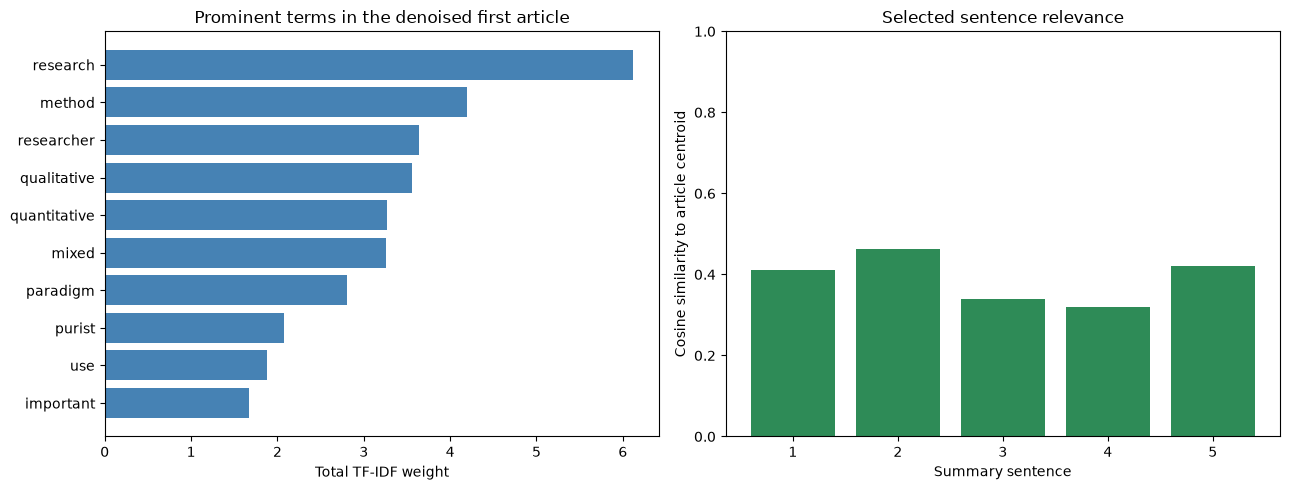

In [4]:
term_weights = np.asarray(tfidf_matrix.sum(axis=0)).ravel()
terms = vectorizer.get_feature_names_out()
top_indices = term_weights.argsort()[-10:]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(terms[top_indices], term_weights[top_indices], color='steelblue')
axes[0].set(title='Prominent terms in the denoised first article', xlabel='Total TF-IDF weight')
axes[1].bar(range(1, len(summary) + 1), sentence_scores[selected_first], color='seagreen')
axes[1].set(title='Selected sentence relevance', xlabel='Summary sentence',
            ylabel='Cosine similarity to article centroid', ylim=(0, 1))
axes[1].set_xticks(range(1, len(summary) + 1))
fig.tight_layout()
plt.show()

**Interpretation.** Read the selected sentences alongside the term chart: the article addresses combining qualitative and quantitative research, methodological pluralism and pragmatism. Relevance scores measure lexical representativeness, not factual accuracy or human-rated summary quality. Filtering long extraction artefacts and penalising redundancy makes the summary more readable, but can omit detailed arguments and limitations.

## 3.4 Aggregate the remaining articles: Latent Semantic Analysis

Fit one shared TF-IDF/LSA model to the denoised sentence features from files 2-5. Truncated SVD finds latent semantic dimensions; sentence scores combine their strength in those dimensions with similarity to their own document's latent centroid. This differs from the direct TF-IDF centroid scoring in 3.3.

Select two sentences per article with a redundancy penalty, ensuring every remaining file contributes to the aggregate. Each extracted sentence retains its source filename. The heatmap shows signed term weights in the latent dimensions; negative values are valid SVD weights, not negative word frequencies. The coverage chart makes source balance visible.

`research_2.txt` is identical to the first article. It is included here because the question asks for the remaining files, and is explicitly treated as duplicate content rather than independent evidence.

In [5]:
from sklearn.decomposition import TruncatedSVD

remaining_articles = df.loc[~df['file_name'].eq('research_1.txt')].copy()
aggregate_candidates = candidate_frame(remaining_articles)
lsa_vectorizer = TfidfVectorizer(min_df=2, sublinear_tf=True)
aggregate_tfidf = lsa_vectorizer.fit_transform(aggregate_candidates['model_text'])
n_topics = min(4, aggregate_tfidf.shape[0] - 1, aggregate_tfidf.shape[1] - 1)
lsa_model = TruncatedSVD(n_components=n_topics, random_state=42)
sentence_topic_strengths = lsa_model.fit_transform(aggregate_tfidf)
latent_strength = np.sqrt(
    (sentence_topic_strengths ** 2 * lsa_model.explained_variance_ratio_).sum(axis=1)
)
latent_strength /= max(latent_strength.max(), np.finfo(float).eps)
lsa_scores = latent_strength.copy()
for file_name in remaining_articles['file_name']:
    indices = aggregate_candidates.index[aggregate_candidates['file_name'].eq(file_name)].to_numpy()
    centroid = sentence_topic_strengths[indices].mean(axis=0, keepdims=True)
    document_relevance = cosine_similarity(sentence_topic_strengths[indices], centroid).ravel()
    lsa_scores[indices] = 0.5 * latent_strength[indices] + 0.5 * document_relevance

# Use lexical cosine to prevent near-identical sentences even when latent axes differ.
aggregate_similarities = cosine_similarity(aggregate_tfidf)
selected_indices = []
for _ in range(2):
    for file_name in remaining_articles['file_name']:
        indices = aggregate_candidates.index[aggregate_candidates['file_name'].eq(file_name)].tolist()
        selected = diverse_choice(indices, lsa_scores, aggregate_similarities, selected_indices)
        if selected is not None:
            selected_indices.append(selected)

aggregate_summary_df = aggregate_candidates.loc[selected_indices].sort_values(
    ['file_name', 'sentence_index']
).copy()
aggregate_summary_df['LSA relevance'] = lsa_scores[aggregate_summary_df.index]
aggregate_summary = aggregate_summary_df['sentence'].tolist()
print('LSA aggregate summary of research_2.txt to research_5.txt:\n')
for number, (_, row) in enumerate(aggregate_summary_df.iterrows(), start=1):
    print(f'{number}. [{row["file_name"]}] {row["sentence"]}\n')

coverage = remaining_articles[['file_name', 'duplicate_of']].set_index('file_name').join(
    aggregate_summary_df.groupby('file_name').size().rename('Selected sentences')
).fillna({'Selected sentences': 0})
coverage['Selected sentences'] = coverage['Selected sentences'].astype(int)
display(coverage)

LSA aggregate summary of research_2.txt to research_5.txt:

1. [research_2.txt] Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.

2. [research_2.txt] Although there are many important paradigmatic differences between qualitative and quantitative research (which have been frequently written about in the Educational Researcher and other places), there are some similarities between the various approaches that are sometimes overlooked.

3. [research_3.txt] Benefits and challenges to reflexivity under three types of researcher's position are discussed and illustrated by means of case examples: (1) reflexivity when researcher shares the experience of study participants, (2) reflexivity when researcher moves from the position of an outsider to the position of an insider in the course of the study, and (3) reflexivity when researcher has no personal familiarity or experience with what is being studied.

4. [res

,duplicate_of,Selected sentences
file_name,,
research_2.txt,research_1.txt,2
research_3.txt,,2
research_4.txt,,2
research_5.txt,,2


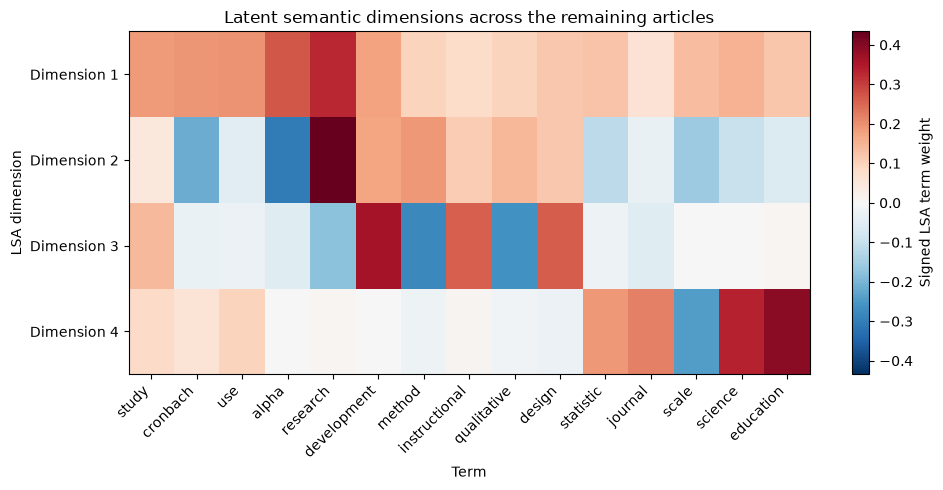

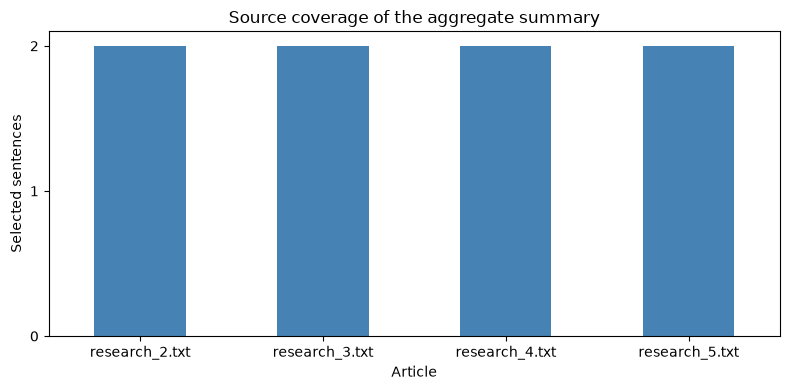

In [6]:
terms = lsa_vectorizer.get_feature_names_out()
top_term_indices = [np.argsort(np.abs(component))[-5:] for component in lsa_model.components_]
all_top_indices = list(dict.fromkeys(index for indices in top_term_indices for index in indices))
term_weights = lsa_model.components_[:, all_top_indices]
limit = np.abs(term_weights).max()

fig, ax = plt.subplots(figsize=(max(10, len(all_top_indices) * 0.6), 5))
image = ax.imshow(term_weights, cmap='RdBu_r', aspect='auto', vmin=-limit, vmax=limit)
fig.colorbar(image, ax=ax, label='Signed LSA term weight')
ax.set_xticks(range(len(all_top_indices)), terms[all_top_indices], rotation=45, ha='right')
ax.set_yticks(range(n_topics), [f'Dimension {number + 1}' for number in range(n_topics)])
ax.set(title='Latent semantic dimensions across the remaining articles', xlabel='Term', ylabel='LSA dimension')
fig.tight_layout()
plt.show()

ax = coverage['Selected sentences'].plot.bar(figsize=(8, 4), color='steelblue', rot=0)
ax.set(title='Source coverage of the aggregate summary', xlabel='Article', ylabel='Selected sentences')
ax.set_yticks(range(3))
plt.tight_layout()
plt.show()

**Interpretation and limitations.** The aggregate brings together mixed-method research (file 2), researcher positionality/reflexivity (file 3), instructional design/development (file 4), and interpretation of Cronbach's alpha (file 5). These are themes in the supplied corpus, not evidence of trends across AI research. Source balancing ensures coverage but is a design choice rather than a measured optimum. LSA provides an extractive summary; the signed latent dimensions need human interpretation, and four distinct document contents are too few to establish general research trends.

### Verification of the Question 3 outputs

The following checks guard against the observed regressions: lost input files, repeated summary passages, table-heading selections and missing source coverage. They verify structural properties and source integrity, not a human evaluation of summary quality.

In [7]:
numeric_example = 'The measured reliability was 0.70 compared with 0.60 in the previous study.'
numeric_cleaned = ' '.join(denoise_article(numeric_example)[0])
assert '0.70' in numeric_cleaned and '0.60' in numeric_cleaned
assert len(df) == len(files) == 5
assert df['file_name'].is_unique and df['text'].str.len().gt(0).all()
assert df['stop_removed'].str.len().gt(0).all()
for _, article in df.iterrows():
    assert hashlib.sha256((corpus_dir / article['file_name']).read_bytes()).hexdigest() == article['content_hash']
    keys = [sentence_key(sentence) for sentence in article['denoised_sentences']]
    assert len(keys) == len(set(keys))
    assert len(article['denoised_sentences']) == len(article['model_sentences'])
assert len(summary) == 5 and len(set(map(sentence_key, summary))) == 5
assert first_similarities[np.ix_(selected_first, selected_first)][~np.eye(len(selected_first), dtype=bool)].max() < 0.80
assert set(aggregate_summary_df['file_name']) == set(remaining_articles['file_name'])
assert coverage['Selected sentences'].eq(2).all()
assert len(set(map(sentence_key, aggregate_summary))) == len(aggregate_summary)
assert not any(re.search(r'\b(?:TABLE|FIGURE)\s+\d', sentence, re.I)
               for sentence in summary + aggregate_summary)
assert not any(re.search(r'\b[1-9]\d?[A-Z][a-z]', sentence) for sentence in summary + aggregate_summary)
print('Question 3 checks passed: all 5 raw files preserved; distinct first-article summary;')
print('all 4 remaining files represented by 2 sentences each; no table-heading selections.')

Question 3 checks passed: all 5 raw files preserved; distinct first-article summary;
all 4 remaining files represented by 2 sentences each; no table-heading selections.


## 4.1 Latent Dirichlet Allocation topic modelling

Latent Dirichlet Allocation (LDA) is used to identify **four topics** in the five research articles. LDA represents each article as a mixture of topics and each topic as a distribution of words. The table below lists the ten highest-probability words for each topic, while the stacked bar chart shows the topic distribution for every document.

In [8]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display

n_topics = 4
n_top_words = 10

lda_vectorizer = CountVectorizer(stop_words='english', max_df=0.95)
document_term_matrix = lda_vectorizer.fit_transform(df['text_lemmatized'])

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method='batch'
)
document_topic_distribution = lda_model.fit_transform(document_term_matrix)

feature_names = lda_vectorizer.get_feature_names_out()
topic_words = {}
for topic_number, topic_weights in enumerate(lda_model.components_, start=1):
    top_indices = topic_weights.argsort()[-n_top_words:][::-1]
    topic_words[f'Topic {topic_number}'] = ', '.join(feature_names[index] for index in top_indices)

topic_word_table = pd.DataFrame(
    {'Topic': list(topic_words), 'Top words': list(topic_words.values())}
)
display(topic_word_table)

topic_distribution = pd.DataFrame(
    document_topic_distribution,
    columns=[f'Topic {number}' for number in range(1, n_topics + 1)],
    index=df['file_name']
).round(3)
print('Topic distribution by document:')
display(topic_distribution)

,Topic,Top words
0,Topic 1,"reflexivity, position, self, share, personal, ..."
1,Topic 2,"future, necessary, enterprise, tradition, back..."
2,Topic 3,"alpha, method, instrument, cronbach, science, ..."
3,Topic 4,"development, design, instructional, developmen..."


Topic distribution by document:


,Topic 1,Topic 2,Topic 3,Topic 4
file_name,,,,
research_1.txt,0.000,0.0,0.999,0.000
research_2.txt,0.000,0.0,0.999,0.000
research_3.txt,0.999,0.0,0.000,0.000
research_4.txt,0.000,0.0,0.000,0.999
research_5.txt,0.000,0.0,1.000,0.000


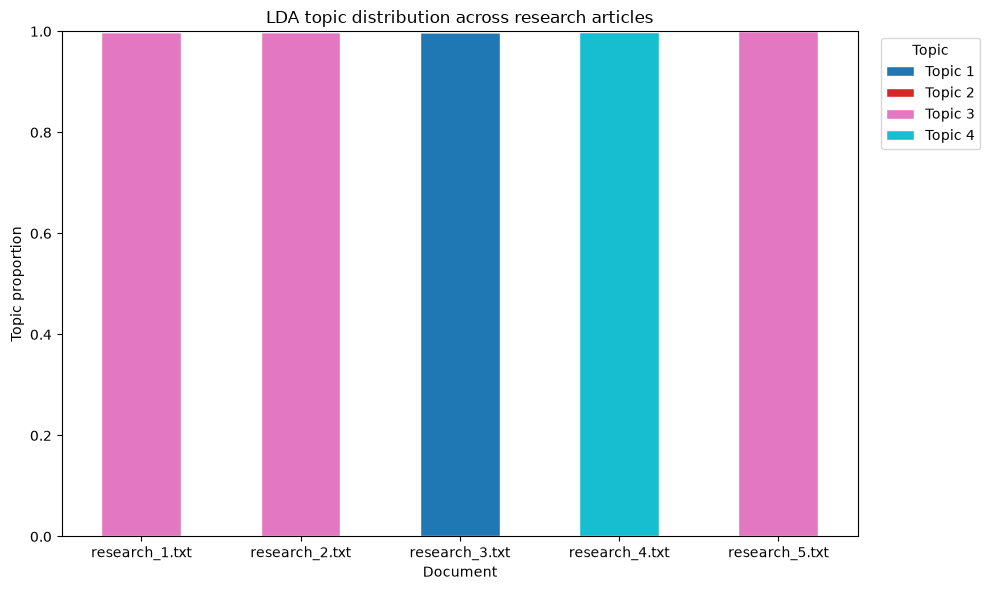

In [9]:
ax = topic_distribution.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='tab10',
    edgecolor='white'
)
ax.set_title('LDA topic distribution across research articles')
ax.set_xlabel('Document')
ax.set_ylabel('Topic proportion')
ax.set_ylim(0, 1)
ax.legend(title='Topic', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4.2 Intertopic Distance Map

The inline preview below is a static intertopic distance map and salient-term chart, so it remains visible in VS Code without JavaScript. Topic-circle **area** represents token-weighted prevalence, and the distances are a two-dimensional t-SNE projection of Jensen-Shannon topic distances (a qualitative view, not exact original distances). The topic numbers match Question 4.1; no topics are reordered by prevalence.

The same prepared LDA results are also exported to **`lda_intertopic_map.html` in this notebook's folder**. Open that file in a web browser for the full interactive pyLDAvis chart: select a topic to inspect its words and adjust the relevance slider. The HTML embeds the installed D3, LDAvis JavaScript and CSS, so it does not need a CDN or internet connection. Opening HTML as source text in the VS Code editor does not run the interactive chart.

The display uses the existing fitted LDA model. Changing its rendering does not improve topic quality: the corpus still has only four distinct document contents, and the negligible topic and merged themes discussed in 4.1 remain limitations.

Interactive map saved. Open this HTML file in a web browser:
c:\Workspace\School Projects\ITNPA\ITNPA_Assignment\Notebooks\Question 3\lda_intertopic_map.html


c:\Workspace\School Projects\ITNPA\ITNPA_Assignment\Notebooks\Question 3\lda_intertopic_map.html

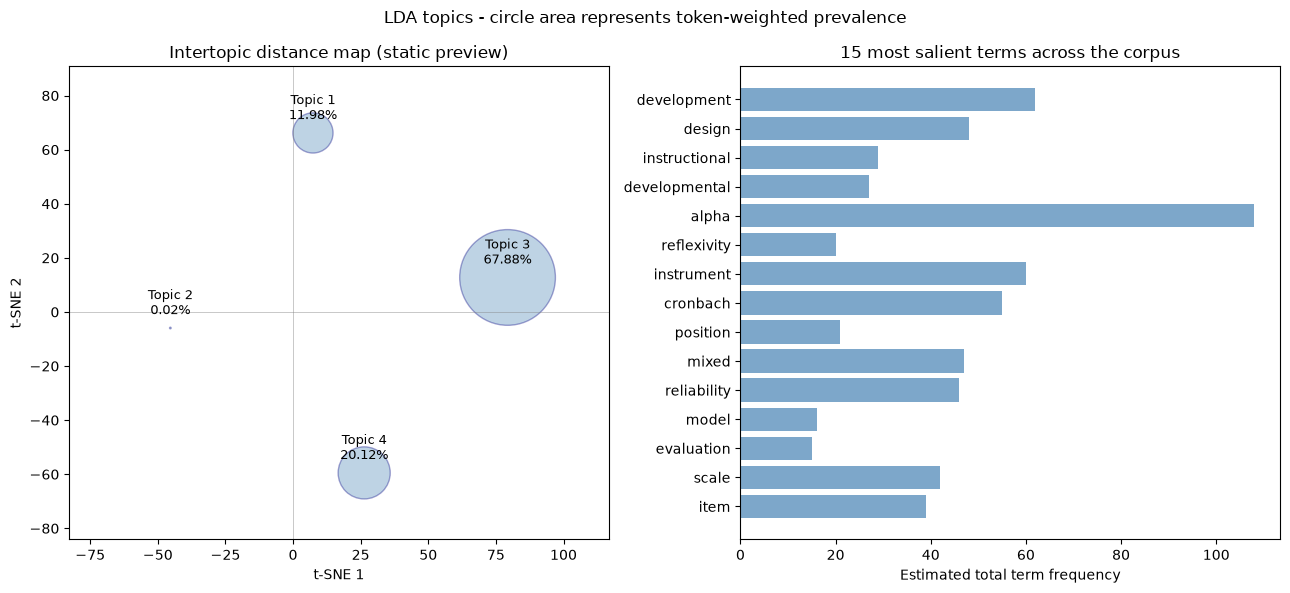

Display checks passed: finite coordinates, matching topic numbers and offline HTML.


In [10]:
from pathlib import Path
import re
import pyLDAvis
import pyLDAvis.lda_model
from pyLDAvis import urls as ldavis_urls
from IPython.display import FileLink, display

lda_visualisation = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    lda_vectorizer,
    mds='tsne',
    plot_opts={'xlab': 't-SNE 1', 'ylab': 't-SNE 2'},
    sort_topics=False,
    n_jobs=1,
)

# Build a standalone page with the matching assets shipped with pyLDAvis.
# Keep their licence notices; no external scripts/styles need to be downloaded.
asset_paths = {
    'd3.js': Path(ldavis_urls.D3_LOCAL),
    'ldavis.js': Path(ldavis_urls.LDAVIS_LOCAL),
    'ldavis.css': Path(ldavis_urls.LDAVIS_CSS_LOCAL),
}
interactive_html = pyLDAvis.prepared_data_to_html(
    lda_visualisation,
    template_type='simple',
    visid='research-lda-map',
    d3_url='d3.js',
    ldavis_url='ldavis.js',
    ldavis_css_url='ldavis.css',
)
for name in ('d3.js', 'ldavis.js'):
    tag = f'<script type="text/javascript" src="{name}"></script>'
    script = asset_paths[name].read_text(encoding='utf-8').replace('</script', r'<\/script')
    assert tag in interactive_html
    interactive_html = interactive_html.replace(tag, f'<script type="text/javascript">{script}</script>')
css_tag = '<link rel="stylesheet" type="text/css" href="ldavis.css">'
assert css_tag in interactive_html
interactive_html = interactive_html.replace(
    css_tag, '<style>' + asset_paths['ldavis.css'].read_text(encoding='utf-8') + '</style>'
)
interactive_html = (
    '<!doctype html><html lang="en"><head><meta charset="utf-8">'
    '<meta name="viewport" content="width=device-width, initial-scale=1">'
    '<title>Research articles - LDA intertopic distance map</title>'
    '<style>body{margin:20px;background:white;color:#111;font-family:Arial,sans-serif;}'
    'svg text{fill:#111;}button,input{color:#111;}#research-lda-map{min-width:1210px;}</style>'
    '</head><body><h1>LDA intertopic distance map</h1>'
    '<p>Select a topic or use Next Topic; adjust the relevance slider to explore its terms. '
    'Topic numbers match Question 4.1. All assets are embedded for offline use.</p>'
    + interactive_html + '</body></html>'
)
assert not re.search(r'<script[^>]+src=|<link[^>]+href=', interactive_html, re.I)
html_path = project_dir / 'Notebooks' / 'Question 3' / 'lda_intertopic_map.html'
html_path.write_text(interactive_html, encoding='utf-8')
print('Interactive map saved. Open this HTML file in a web browser:')
print(html_path)
try:
    link_path = html_path.relative_to(Path.cwd())
except ValueError:
    link_path = html_path
display(FileLink(str(link_path), result_html_prefix='Interactive HTML: '))

# A JavaScript-free preview for VS Code and exported notebook documents.
coordinates = lda_visualisation.topic_coordinates
salient_terms = lda_visualisation.topic_info.query("Category == 'Default'").head(15).iloc[::-1]
fig, (map_ax, terms_ax) = plt.subplots(1, 2, figsize=(13, 6))
map_ax.scatter(coordinates['x'], coordinates['y'],
               s=coordinates['Freq'] * 70, alpha=0.35,
               color='steelblue', edgecolors='navy')
for _, topic in coordinates.iterrows():
    map_ax.annotate(
        f'Topic {int(topic["topics"])}\n{topic["Freq"]:.2f}%',
        (topic['x'], topic['y']), xytext=(0, 10), textcoords='offset points',
        ha='center', fontsize=9,
    )
map_ax.axhline(0, color='grey', linewidth=0.6, alpha=0.5)
map_ax.axvline(0, color='grey', linewidth=0.6, alpha=0.5)
map_ax.set(title='Intertopic distance map (static preview)', xlabel='t-SNE 1', ylabel='t-SNE 2')
map_ax.set_aspect('equal', adjustable='datalim')
map_ax.margins(0.30)
terms_ax.barh(salient_terms['Term'], salient_terms['Total'], color='steelblue', alpha=0.7)
terms_ax.set(title='15 most salient terms across the corpus', xlabel='Estimated total term frequency')
fig.suptitle('LDA topics - circle area represents token-weighted prevalence', fontsize=12)
fig.tight_layout()
plt.show()

assert coordinates['topics'].tolist() == list(range(1, lda_model.n_components + 1))
assert np.isfinite(coordinates[['x', 'y', 'Freq']].to_numpy()).all()
assert np.isclose(coordinates['Freq'].sum(), 100)
assert html_path.is_file()
print('Display checks passed: finite coordinates, matching topic numbers and offline HTML.')